# 02 · Out-of-sample signal research

Purged chronological folds; all preprocessing fits training history. This is one stock-day, not evidence of a stable market edge.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

from market_microstructure.utils.config import load_config
from market_microstructure.utils.paths import PROJECT_ROOT

ROOT = PROJECT_ROOT
config = load_config()
def table(name):
    return pd.read_csv(ROOT / 'outputs' / 'tables' / f'{name}.csv')
def figure(name):
    display(Image(filename=str(ROOT / 'outputs' / 'figures' / f'{name}.png')))
features = pd.read_parquet(ROOT / config['data']['features_path'])
assert set(features.asset) == {'000400.SZ'}
assert features.timestamp.dt.tz is not None


In [2]:
predictions = pd.read_parquet(ROOT / 'data/processed/predictions.parquet')
assert not predictions.duplicated(['model','asset','timestamp']).any()
display(table('model_oos_summary'))
display(table('signal_summary'))
display(table('feature_ablation_summary'))

,model,rows,labeled_rows,signal_ic,accuracy,balanced_accuracy,precision,recall,roc_auc,r2,mse_bps2,mae_bps,pearson,spearman
0,forest,10500,10490,0.259630,0.519447,0.492011,0.542616,0.492011,0.687041,NaN,NaN,NaN,NaN,NaN
1,linear,10500,10490,0.254682,NaN,NaN,NaN,NaN,NaN,0.065733,113.615899,6.968937,0.262005,0.320193
2,logistic,10500,10490,0.302810,0.526597,0.515058,0.520795,0.515058,0.699860,NaN,NaN,NaN,NaN,NaN


,model,ic,rank_ic,ic_low,ic_high
0,forest,0.259630,0.323510,0.219033,0.307360
1,linear,0.254682,0.320193,0.199600,0.304919
2,logistic,0.302810,0.353715,0.241114,0.359298


,feature_set,feature_count,model,rows,labeled_rows,signal_ic,accuracy,balanced_accuracy,precision,recall,roc_auc
0,imbalance_only,1,logistic,10500,10490,0.159436,0.458532,0.414895,0.304550,0.414895,0.569250
1,imbalance_spread_depth,3,logistic,10500,10490,0.194733,0.445281,0.414120,0.407175,0.414120,0.614778
2,full_features,13,logistic,10500,10490,0.302810,0.526597,0.515058,0.520795,0.515058,0.699860


## Train-only fit and overlap boundaries

A real first-fold logistic model is fitted below using exactly the purged training indices. It is an inspectable example, not a backfill of saved OOS predictions.

In [3]:
from market_microstructure.features.feature_pipeline import feature_columns
from market_microstructure.models.estimators import make_model
from market_microstructure.models.validation import WalkForwardConfig, walk_forward_splits

fold = next(walk_forward_splits(features, WalkForwardConfig(**config['validation'])))
train = features.iloc[fold.train].dropna(subset=['direction'])
assert train.label_end.max() < fold.validation_start
assert features.iloc[fold.validation].label_end.max() < fold.test_start
columns = feature_columns(features)
assert not {'future_return_bps','direction','label_end'} & set(columns)
model = make_model('logistic', config['model'], config['seed'])
model.fit(train[columns], train.direction)
frozen_mean = model.named_steps['scaler'].mean_.copy()
model.predict_proba(features.iloc[fold.test][columns])
np.testing.assert_array_equal(frozen_mean, model.named_steps['scaler'].mean_)
display(table('fold_audit').head(6))
print('Training scaler remains frozen on unseen data.')

,fold,model,train_rows,train_last_timestamp,train_max_label_end,validation_start,validation_max_label_end,test_start,test_end
0,0,linear,2480,2022-06-01 02:11:25+00:00,2022-06-01 02:11:35+00:00,2022-06-01 02:11:46+00:00,2022-06-01 02:19:57+00:00,2022-06-01 02:20:08+00:00,2022-06-01 02:32:38+00:00
1,0,logistic,2480,2022-06-01 02:11:25+00:00,2022-06-01 02:11:35+00:00,2022-06-01 02:11:46+00:00,2022-06-01 02:19:57+00:00,2022-06-01 02:20:08+00:00,2022-06-01 02:32:38+00:00
2,0,forest,2480,2022-06-01 02:11:25+00:00,2022-06-01 02:11:35+00:00,2022-06-01 02:11:46+00:00,2022-06-01 02:19:57+00:00,2022-06-01 02:20:08+00:00,2022-06-01 02:32:38+00:00
3,1,linear,3230,2022-06-01 02:23:57+00:00,2022-06-01 02:24:07+00:00,2022-06-01 02:24:18+00:00,2022-06-01 02:32:28+00:00,2022-06-01 02:32:39+00:00,2022-06-01 02:45:08+00:00
4,1,logistic,3230,2022-06-01 02:23:57+00:00,2022-06-01 02:24:07+00:00,2022-06-01 02:24:18+00:00,2022-06-01 02:32:28+00:00,2022-06-01 02:32:39+00:00,2022-06-01 02:45:08+00:00
5,1,forest,3230,2022-06-01 02:23:57+00:00,2022-06-01 02:24:07+00:00,2022-06-01 02:24:18+00:00,2022-06-01 02:32:28+00:00,2022-06-01 02:32:39+00:00,2022-06-01 02:45:08+00:00


Training scaler remains frozen on unseen data.


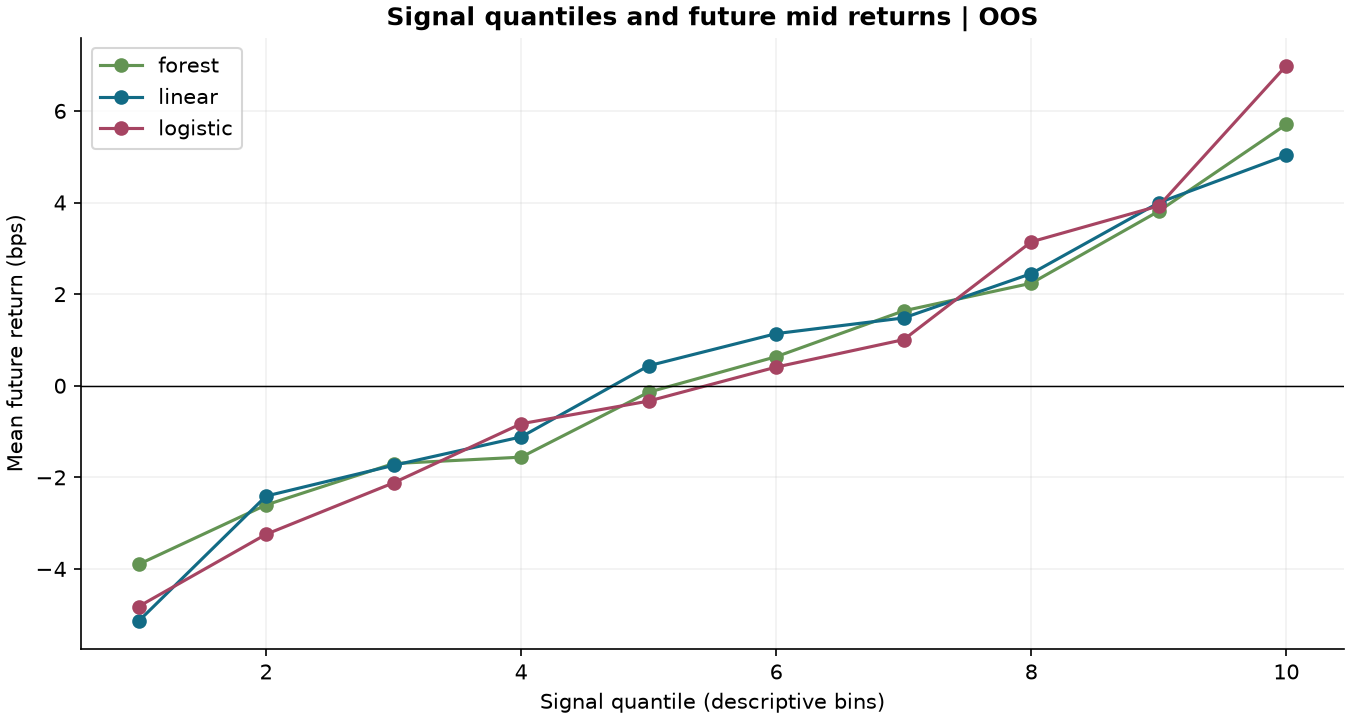

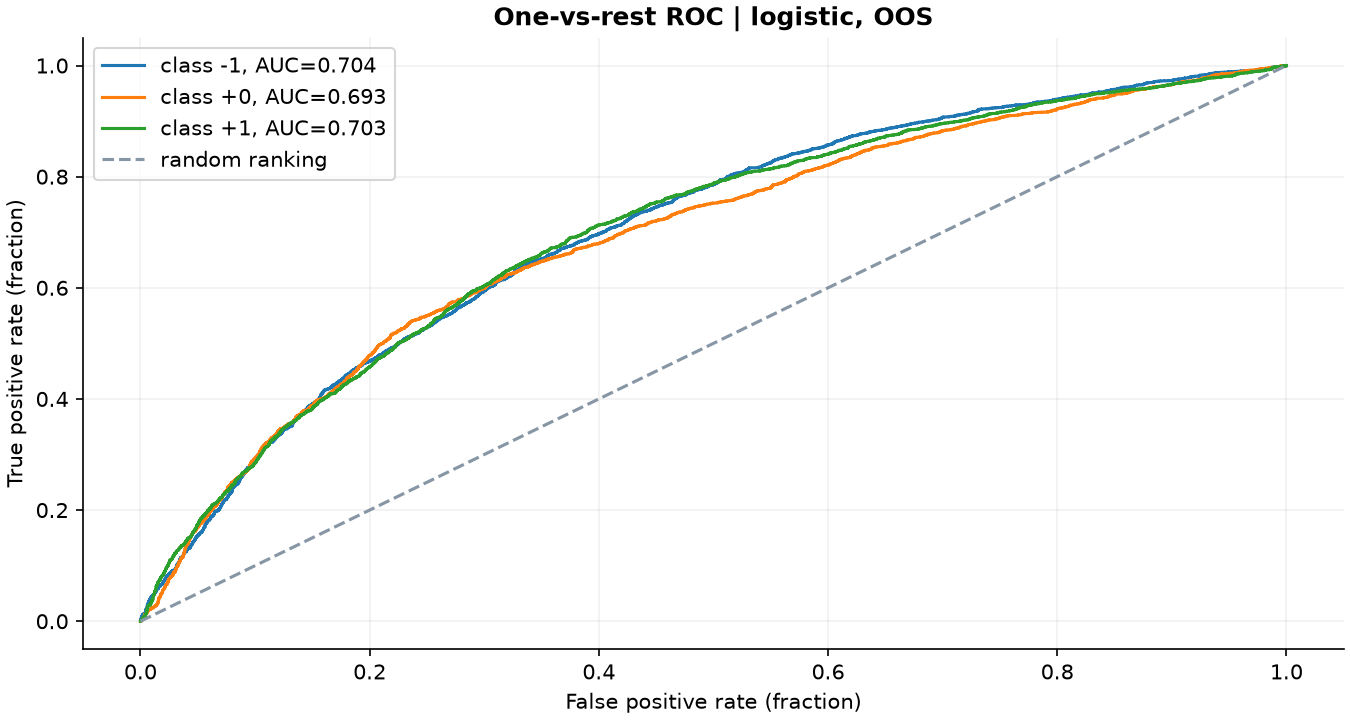

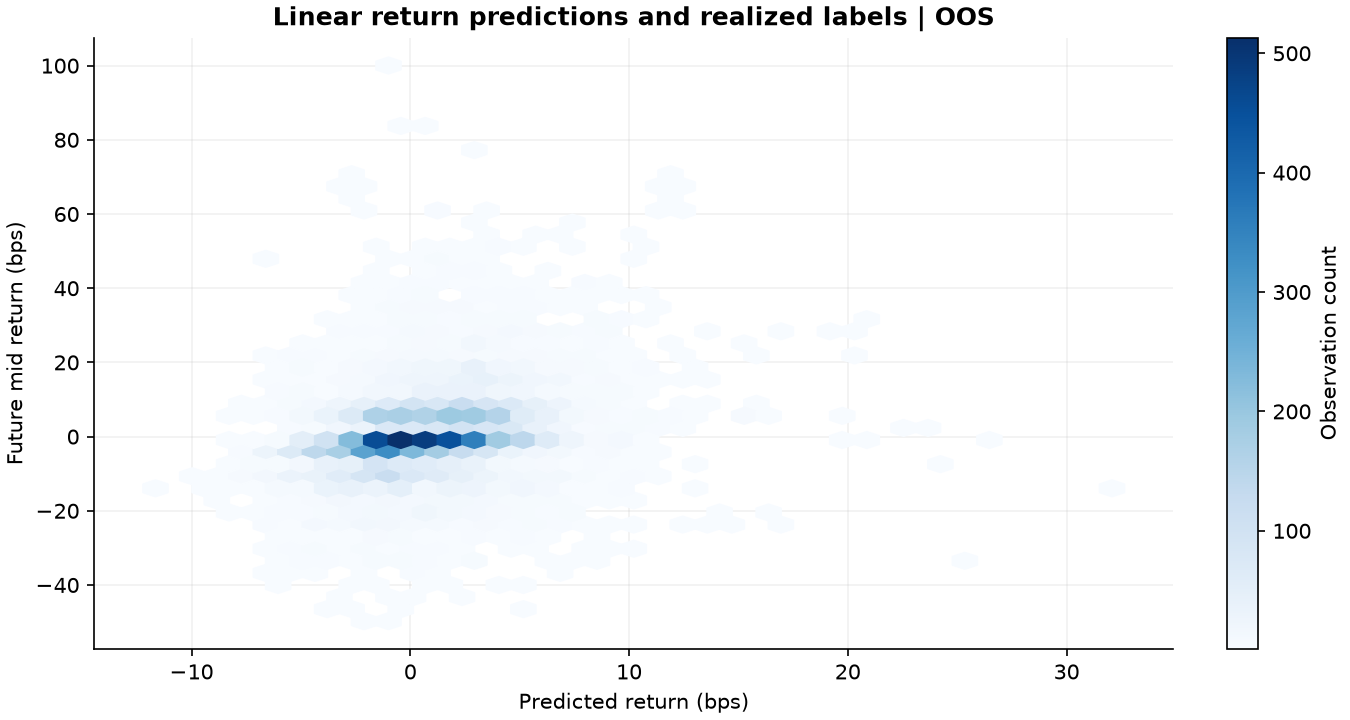

In [4]:
figure('signal_quantile_vs_future_return')
figure('roc_curve')
figure('prediction_vs_realized_return')

## Decay and stability

Overlapping labels remain dependent. The bootstrap is within-day timestamp-block uncertainty. Half-life is a sampled half-peak crossing rather than an exponential fit.

,asset,peak_horizon_events,peak_ic,half_life_events,censored
0,000400.SZ,10,0.30281,50,False


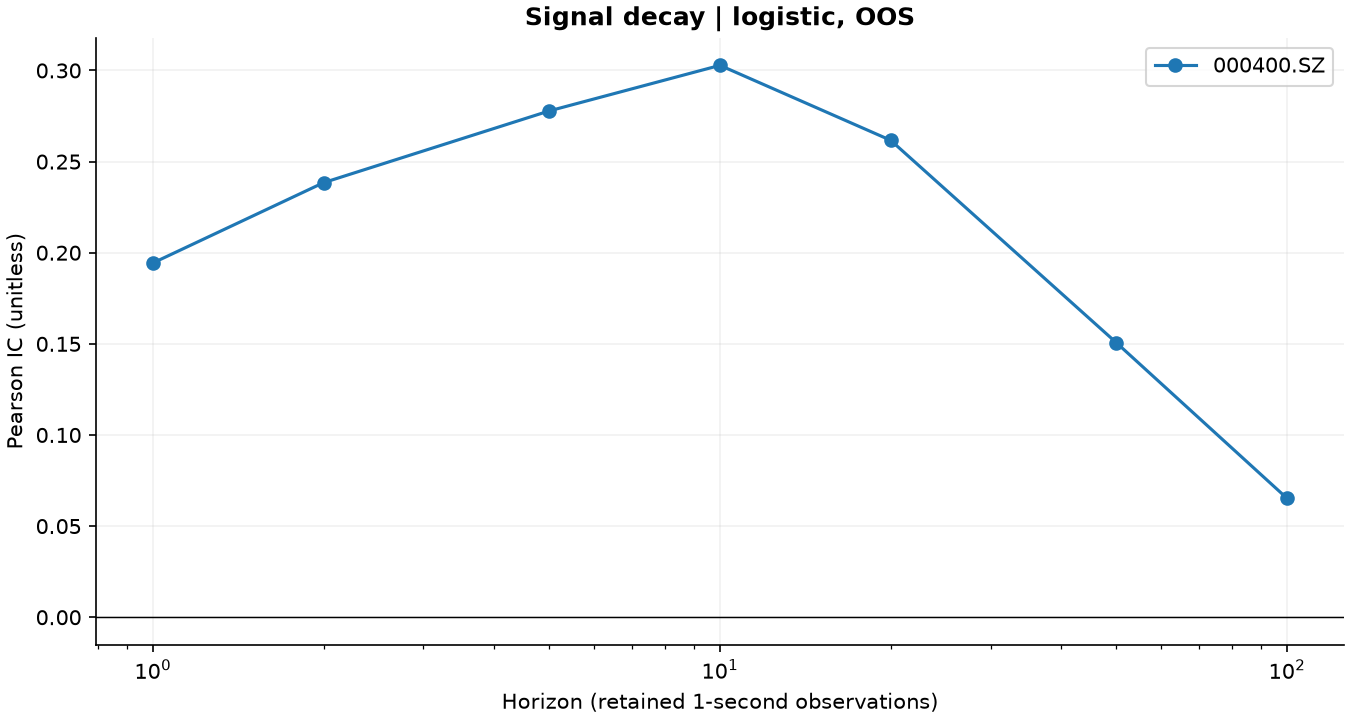

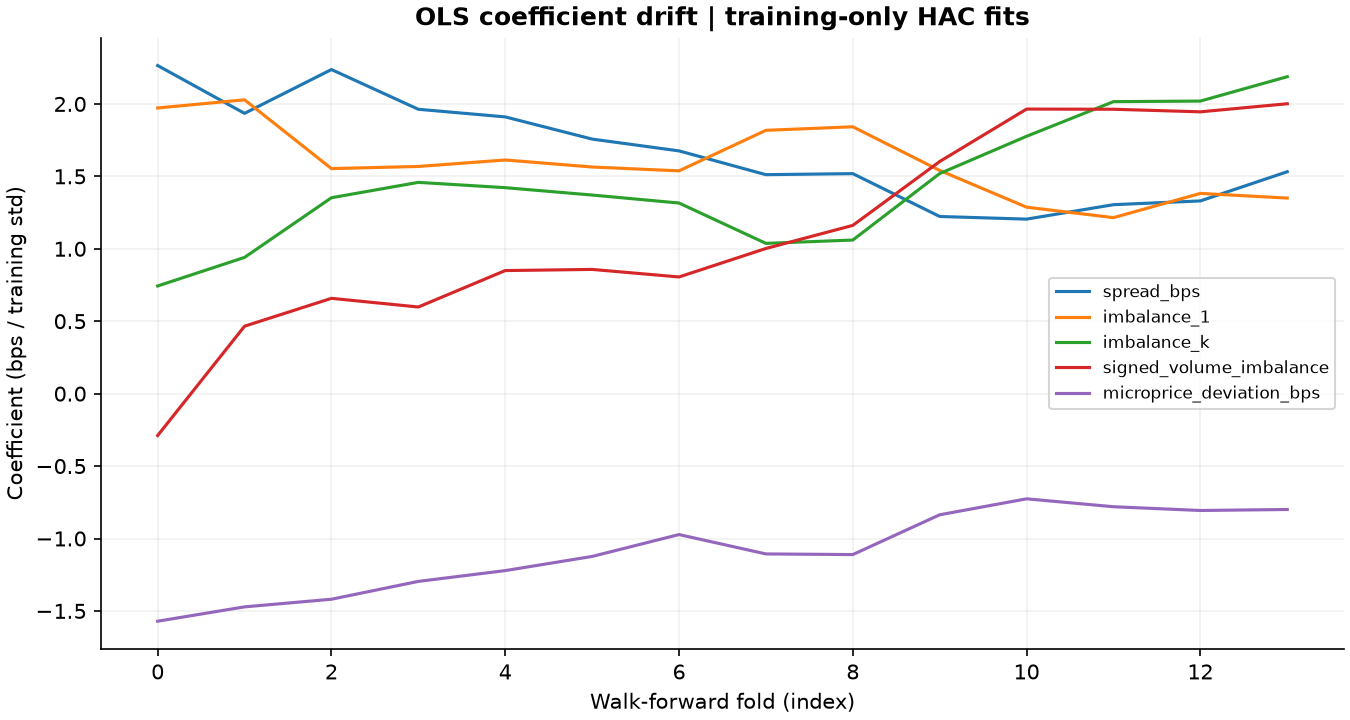

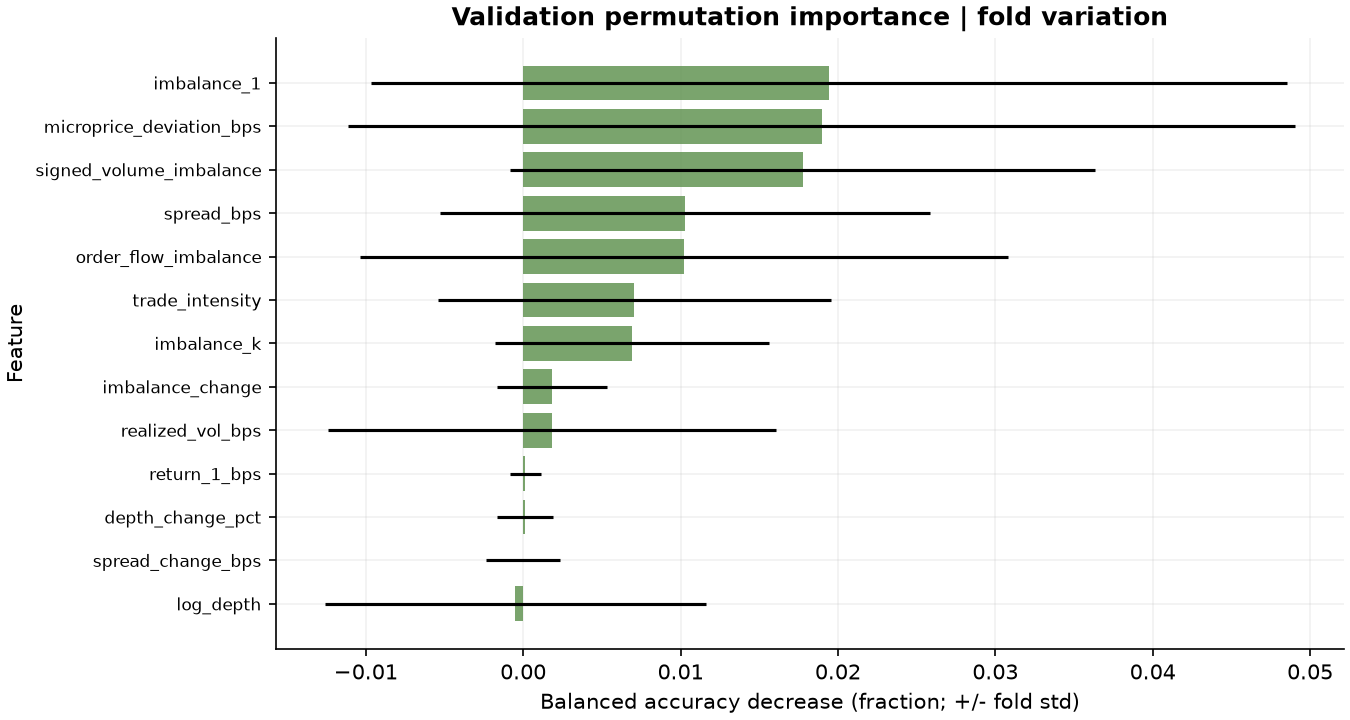

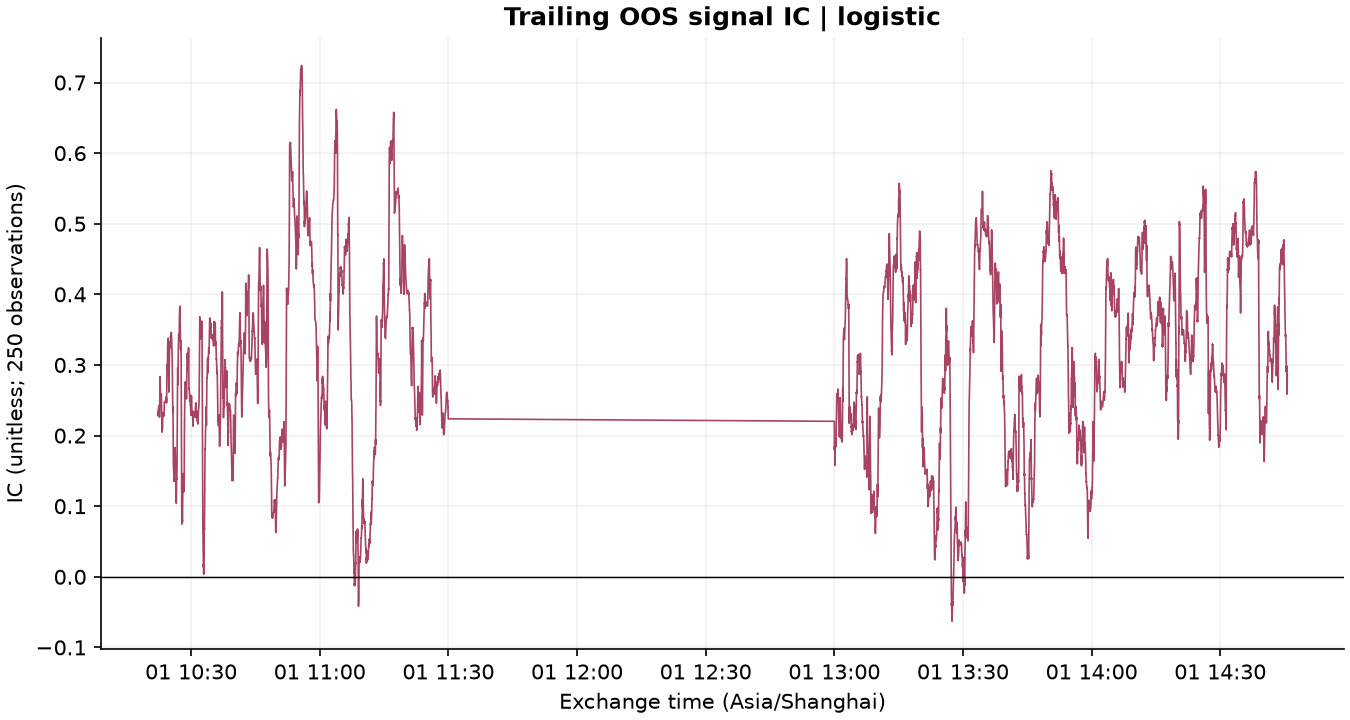

In [5]:
display(table('signal_half_life'))
figure('signal_decay_curve')
figure('coefficient_stability')
figure('feature_importance')
figure('rolling_ic')